# Seismic Travel Time Tomography via Fast Marching - Linear Solvers, Smoothing and Damping in Gauss–Newton

[![Open In Colab](https://img.shields.io/badge/open%20in-Colab-b5e2fa?logo=googlecolab&style=flat-square&color=ffd670)](https://colab.research.google.com/github/inlab-geo/cofi-examples/blob/main/examples/fmm_tomography/fmm_tomography_solver_regularization.ipynb)

<!-- Again, please don't touch the markdown cell above. We'll generate badge 
     automatically from the above cell. -->

<!-- This cell describes things related to environment setup, so please add more text 
     if something special (not listed below) is needed to run this notebook -->

> If you are running this notebook locally, make sure you've followed [steps here](https://github.com/inlab-geo/cofi-examples#run-the-examples-with-cofi-locally)
to set up the environment. (This [environment.yml](https://github.com/inlab-geo/cofi-examples/blob/main/envs/environment.yml) file
specifies a list of packages required to run the notebooks)

<!-- TODO - background introduction for this problem. -->

This notebook studies how to regularise a Gauss–Newton travel-time tomography. It first shows how the linear solver
inside Gauss–Newton affects the result when the objective function only includes smoothing regularisation and damping
regularisation is absent, and then how adding a damping term removes the left-to-right trend that an exact solver
leaves in the model. It is a companion to
[`fmm_tomography_regularization_discussion.ipynb`](fmm_tomography_regularization_discussion.ipynb), which inverts the
same data with smoothing regularisation and, as an alternative, with a Gaussian prior.

Every Gauss–Newton step solves a linear system for the model update. The system can be solved exactly, for example
with `scipy.linalg.solve`, or approximately with an iterative solver such as `scipy.sparse.linalg.minres`, which
stops once the update is accurate to a set tolerance. The choice matters when some change to the model is seen
neither by the data nor by the regularisation, and with smoothing only, this problem has one: a slowness ramp from
left to right (section 2).

We run the same smoothing-only inversion with each solver (section 3) and compare three things: whether
Gauss–Newton converges, whether the data can be fitted to their noise level ($\chi^2/N = 1$), and what the models look
like. We then add a damping term (section 4): we choose its weight from the size of the model, show why the smoothing
must still dominate, and tune the overall weight by cooling until $\chi^2/N\approx1$.

## 0. Import modules

In [1]:
# -------------------------------------------------------- #
#                                                          #
#     Uncomment below to set up environment on "colab"     #
#                                                          #
# -------------------------------------------------------- #

# !pip install -U cofi pyfm2d

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg
import scipy.sparse.linalg

import cofi
import pyfm2d as wt

## 1. Problem setup

The data, geometry and noise level are those of the other FMM examples: 10 sources on the left edge, 10
receivers on the right edge, 100 travel times, and a noise standard deviation of $8\times10^{-6}$ s.

Gauss–Newton (section 3) minimises the objective

$$\phi(m)=\chi^2(m)+\beta\,\|W(m-m_0)\|^2,\qquad\chi^2(m)=\sum_{i=1}^{N}\left(\frac{d_i-g_i(m)}{\sigma}\right)^2 .$$

- $m$ is the slowness model, one value in each of the $M=32\times48$ cells, and $m_0$ is the constant starting model.
- $d_i$ is the $i$-th of the $N=100$ observed travel times, $g_i(m)$ is the travel time that FMM computes for model
  $m$, and $\sigma=8\times10^{-6}$ s is the noise standard deviation.
- $\chi^2$ is the data misfit in units of the noise. If the residuals were pure noise, each term of the sum would be
  about 1 on average, so a model that fits the data to their noise level has $\chi^2/N\approx1$.
- $W$ is CoFI's `"smoothing"` operator: two stacked finite-difference matrices, one taking the second difference of
  the model along $x$ and the other along $y$, at every cell. $\|W(m-m_0)\|^2$ is therefore the sum of the squared
  second differences of the model change: its roughness.
- $\beta$ is the smoothing weight. In sections 2 and 3, smoothing is the only regularisation;
  section 4 adds damping.

In [3]:
loaded = np.load("../../data/travel_time_tomography/nonlinear_tomo_example.npz")
extent, sources, receivers = loaded["extent"], loaded["sources"], loaded["receivers"]
obstimes = loaded["_data"]                                   # observed travel times
s_true = loaded["_strue"].flatten()                          # true slowness, used only to judge the results
m0 = loaded["_sstart"].flatten()                             # constant starting slowness
model_shape, data_size = loaded["_sstart"].shape, len(loaded["_data"])
s0 = m0.mean()
sigma = 8e-6                                                 # noise standard deviation (s)

def fmm_forward_and_jacobian(slowness):
    """Travel times and their Frechet derivatives from a single FMM run"""
    options = wt.WaveTrackerOptions(paths=True, frechet=True, cartesian=True, quiet=True)   # quiet: no ray-path warnings
    result = wt.calc_wavefronts(1./slowness.reshape(model_shape), receivers, sources,
                                extent=extent, options=options)
    return result.ttimes, result.frechet.toarray()

W = cofi.utils.QuadraticReg(model_shape=model_shape, weighting_matrix="smoothing").matrix
WtW = (W.T @ W).toarray()

# the linear-in-x pattern, to measure how much left-to-right trend a model carries
nx, ny = model_shape
cell_size = (extent[1] - extent[0]) / nx
x_cell = np.repeat((np.arange(nx) + 0.5) * cell_size, ny)
x_ramp = (x_cell - x_cell.mean()) / np.linalg.norm(x_cell - x_cell.mean())

def left_to_right_trend(model):
    """Slowness change from the left edge to the right edge carried by the linear-in-x part of the model,
    as a fraction of the starting slowness"""
    return (x_ramp @ (model - m0)) * (x_ramp.max() - x_ramp.min()) / s0

`left_to_right_trend` measures how much left-to-right ramp (linear trend in $x$) a model's slowness change $m-m_0$ carries. `x_ramp` is the ramp as a unit vector: each cell's $x$-coordinate minus their mean, divided by the norm,

$$(x_\text{ramp})_k=\frac{x_k-\bar x}{\sqrt{\sum_{j=1}^{M}(x_j-\bar x)^2}},\qquad \bar x=\frac{1}{M}\sum_{j=1}^{M}x_j,$$

where $x_k$ is the $x$-coordinate of the centre of cell $k$ and $M=32\times48=1536$ is the number of cells. For a
model $m$, `left_to_right_trend` returns

$$\text{trend}(m)=\frac{x_\text{ramp}^T(m-m_0)\,\big(\max x_\text{ramp}-\min x_\text{ramp}\big)}{s_0}.$$

The projection $x_\text{ramp}^T(m-m_0)$ is proportional to the slope of the straight line in $x$ that best fits the
model change (least squares over all cells). Multiplying by $\max x_\text{ramp}-\min x_\text{ramp}$, the difference
between the largest and smallest components of $x_\text{ramp}$, turns it into the change of that line from the
leftmost to the rightmost cells, and dividing by the starting slowness $s_0$ expresses that change as a fraction of
$s_0$. The results report it in percent; a negative value means the slowness decreases from left to right, and the
true model's trend is $-3.2\%$.

## 2. What neither the data nor the smoothing can see

All sources are on the left edge and all receivers on the right edge, so every ray crosses the model from left to
right. Consider a slowness ramp that increases steadily from left to right. Along any ray it shortens the travel
time over the left half and lengthens it by the same amount over the right half, so the travel time at the
receiver hardly changes. The smoothing does not penalise the ramp either: it measures curvature, and a straight
ramp has none.

The numbers below compare the ramp with a constant slowness shift of the same size, using the Jacobian $J$ of the
starting model and the smoothing operator $W$.

In [4]:
one = np.ones(m0.size) / np.sqrt(m0.size)                   # constant shift, unit size like x_ramp
_, J_start = fmm_forward_and_jacobian(m0)
JtJ_start = J_start.T @ J_start

print(f"smoothing of the ramp, |W x_ramp|:                              {np.linalg.norm(W @ x_ramp):.1e}")
print(f"travel-time change, |J x_ramp| / |J one|:                       "
      f"{np.linalg.norm(J_start @ x_ramp) / np.linalg.norm(J_start @ one):.2e}")
print(f"misfit curvature, (x_ramp^T J^T J x_ramp) / (one^T J^T J one):  "
      f"{(x_ramp @ JtJ_start @ x_ramp) / (one @ JtJ_start @ one):.2e}")

smoothing of the ramp, |W x_ramp|:                              2.1e-16
travel-time change, |J x_ramp| / |J one|:                       2.36e-03
misfit curvature, (x_ramp^T J^T J x_ramp) / (one^T J^T J one):  5.56e-06


The figure below shows the ramp with the rays of the starting model (left), and the travel-time change it causes for
each of the 100 rays (right), compared with a constant shift and a bottom-to-top ramp of the same size. For a model
change $v$, $(Jv)_i$ is the change in the travel time of ray $i$, which is $v$ added up along the ray. It is
plotted in units of the noise standard deviation $\sigma$; the grey band is $\pm1$.

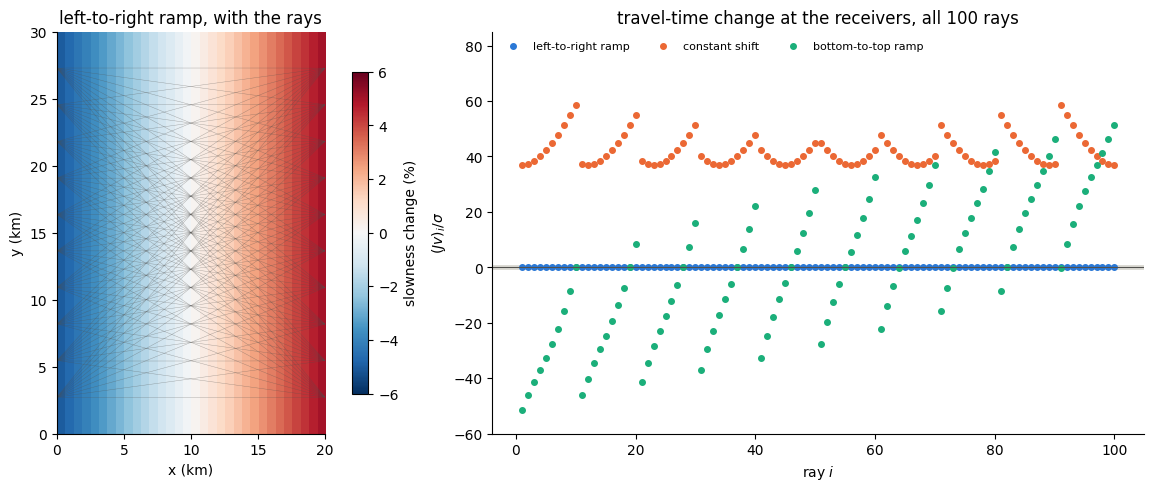

In [5]:
y_cell = np.tile((np.arange(ny) + 0.5) * cell_size, nx)       # y-coordinate of each cell centre
ramp = 0.05 * s0 * (x_cell - x_cell.mean()) / (x_cell.max() - x_cell.mean())   # -5% at the left edge, +5% at the right
size = np.sqrt(np.mean(ramp**2))
patterns = {"left-to-right ramp": ramp,
            "constant shift": np.full(m0.size, size),
            "bottom-to-top ramp": (y_cell - y_cell.mean()) / np.sqrt(np.mean((y_cell - y_cell.mean())**2)) * size}
pattern_colours = {"left-to-right ramp": "#2a78d6", "constant shift": "#eb6834", "bottom-to-top ramp": "#1baf7a"}

start_paths = [np.asarray(p) for p in wt.calc_wavefronts(1./m0.reshape(model_shape), receivers, sources, extent=extent,
               options=wt.WaveTrackerOptions(paths=True, cartesian=True, quiet=True)).paths]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True, gridspec_kw={"width_ratios": [0.8, 1.4]})

im = axes[0].imshow(100 * ramp.reshape(model_shape).T / s0, origin="lower", extent=extent, cmap="RdBu_r", vmin=-6, vmax=6)
for path in start_paths:
    axes[0].plot(*path.T, color="#52514e", lw=0.3, alpha=0.5)
axes[0].set(title="left-to-right ramp, with the rays", xlabel="x (km)", ylabel="y (km)")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="slowness change (%)")

for name, field in patterns.items():
    axes[1].plot(np.arange(1, data_size + 1), J_start @ field / sigma, "o", ms=4, color=pattern_colours[name], label=name)
axes[1].axhspan(-1, 1, color="#dcdbd5", lw=0)                # +- one noise standard deviation
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set(title="travel-time change at the receivers, all 100 rays", xlabel="ray $i$",
            ylabel=r"$(Jv)_i/\sigma$", ylim=(-60, 85))
axes[1].legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
for ax in axes:
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
plt.show()

The left-to-right ramp is the slowness change $v = a\,(x-10)$ for $x$ between 0 and 20 km ($x$ in km). It is
negative over the left half of the model, zero along the middle ($x = 10$ km) and positive over the right half; $a$
sets its size, here $\pm5\%$ of the starting slowness at the edges. In the starting model every ray is straight and
runs from the left edge ($x = 0$) to the right edge ($x = 20$ km), so along a ray of length $L$ a step $dx$ covers
a length $dl = (L/20)\,dx$ of the ray. For every ray, then,

$$(Jv)_i=\int_{\text{ray}} v\,dl=\frac{L}{20}\int_0^{20} a\,(x-10)\,dx=0$$

Each ray loses over the left half exactly what it gains over the right half, whatever its slope. The blue points
confirm it: all 100 changes are a small fraction of the noise, while a constant shift or a bottom-to-top ramp of the
same size changes the travel times by tens of noise standard deviations.

Because $Jv\approx0$, also $J^TJ\,v=J^T(Jv)\approx0$: the ramp is just as invisible to $J^TJ$, the data part of the
Gauss–Newton Hessian (section 3) $$H = 2J^TJ/\sigma^2+2\beta W^TW$$

The curvature of the data misfit along $v$ is $v^TJ^TJ\,v=(Jv)^T(Jv)=\|Jv\|^2,$ the square of the travel-time change, which is why the third number above is the square of the second. The smoothing adds no curvature either, because $Wv=0$. So the Hessian has almost no curvature along the ramp, and almost nothing in a smoothing-only objective fixes its size. How each linear solver deals with such a direction is what the rest of this notebook is about.

## 3. Gauss–Newton with two linear solvers

### 3.1 Setup

Both runs take full Gauss–Newton steps from the starting model, as `cofi.simple_newton` does with
`step_length=1`. The only difference is how the linear system of each step is solved:

- **minres**: iterative, stopping at its default relative tolerance of $10^{-5}$;
- **exact solve**: `scipy.linalg.solve`.

A run counts as converged when no cell changes by more than $10^{-6}$ (0.2% of the starting slowness) in a
step, within 80 iterations.

We use fifteen smoothing weights: ten spaced logarithmically from $\beta=5\times10^2$ to $5\times10^{10}$, and five
larger ones up to $5\times10^{11}$. All of the first ten fit the data more closely than the noise ($\chi^2/N<1$). The five larger weights take the fit past $\chi^2/N=1$.

In [6]:
solvers = {
    "minres": lambda H, rhs: scipy.sparse.linalg.minres(H, rhs)[0],          # needs only products H @ x
    "exact solve": lambda H, rhs: scipy.linalg.solve(H, rhs, assume_a="sym"),
}

def gauss_newton(beta, solve, num_iterations=80, tol=1e-6):
    """Full Gauss-Newton steps from the starting model with smoothing weight beta"""
    model = m0.copy()
    for _ in range(num_iterations):
        t, J = fmm_forward_and_jacobian(model)
        residual, x = obstimes - t, model - m0
        hessian = 2 * J.T @ J / sigma**2 + 2 * beta * WtW
        gradient = -2 * J.T @ residual / sigma**2 + 2 * beta * WtW @ x   # W m0 = 0 for the constant m0
        step = solve(hessian, -gradient)
        if np.min(model + step) <= 0:                                     # negative slowness: stop
            return {"model": model, "converged": False, "failed": True}
        model = model + step
        if np.abs(step).max() < tol:
            break
    residual = obstimes - fmm_forward_and_jacobian(model)[0]
    return {"model": model, "converged": bool(np.abs(step).max() < tol), "failed": False,
            "chi2": residual @ residual / sigma**2, "roughness": (model - m0) @ WtW @ (model - m0)}

betas = list(5e6 * np.logspace(-4, 4, 10)) + [1e11, 2e11, 3e11, 4e11, 5e11]   # ten weights from 5e2 to 5e10, plus five larger ones
runs = {name: {beta: gauss_newton(beta, solve) for beta in betas} for name, solve in solvers.items()}

print(f"{'solver':>12} {'beta':>9} {'converged':>10} {'chi2/N':>8} {'trend':>8} {'error':>7}")
for name, by_beta in runs.items():
    for beta, r in by_beta.items():
        if r["failed"]:
            print(f"{name:>12} {beta:9.1e}   failed (a step made the slowness negative)")
            continue
        error = np.sqrt(np.mean((r["model"] - s_true)**2)) / s0
        print(f"{name:>12} {beta:9.1e} {str(r['converged']):>10} {r['chi2'] / data_size:8.2f} "
              f"{left_to_right_trend(r['model']):8.1%} {error:7.1%}")
print(f"\ntrue model: left-to-right trend {left_to_right_trend(s_true):.1%}")
print("trend = slowness change from left to right edge from the linear-in-x part; "
      "error = rms difference from the true model; both as fractions of the starting slowness")

/tmp/ipykernel_120933/4030841872.py:3: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.1106070118845886e-16.
  "exact solve": lambda H, rhs: scipy.linalg.solve(H, rhs, assume_a="sym"),


      solver      beta  converged   chi2/N    trend   error
      minres   5.0e+02       True     0.00    -0.0%    2.7%
      minres   3.9e+03       True     0.00    -0.0%    2.7%
      minres   3.0e+04       True     0.00    -0.0%    2.7%
      minres   2.3e+05       True     0.00    -0.0%    2.6%
      minres   1.8e+06       True     0.00    -0.0%    2.5%
      minres   1.4e+07       True     0.00    -0.0%    2.4%
      minres   1.1e+08       True     0.00    -0.1%    2.3%
      minres   8.3e+08       True     0.00    -0.2%    2.3%
      minres   6.5e+09       True     0.02    -0.3%    2.3%
      minres   5.0e+10       True     0.16    -0.4%    2.2%
      minres   1.0e+11       True     0.29    -0.4%    2.2%
      minres   2.0e+11       True     0.58    -0.4%    2.2%
      minres   3.0e+11       True     0.89    -0.3%    2.2%
      minres   4.0e+11       True     1.20    -0.3%    2.2%
      minres   5.0e+11       True     1.52    -0.3%    2.3%
 exact solve   5.0e+02      False     0.

### 3.2 Results

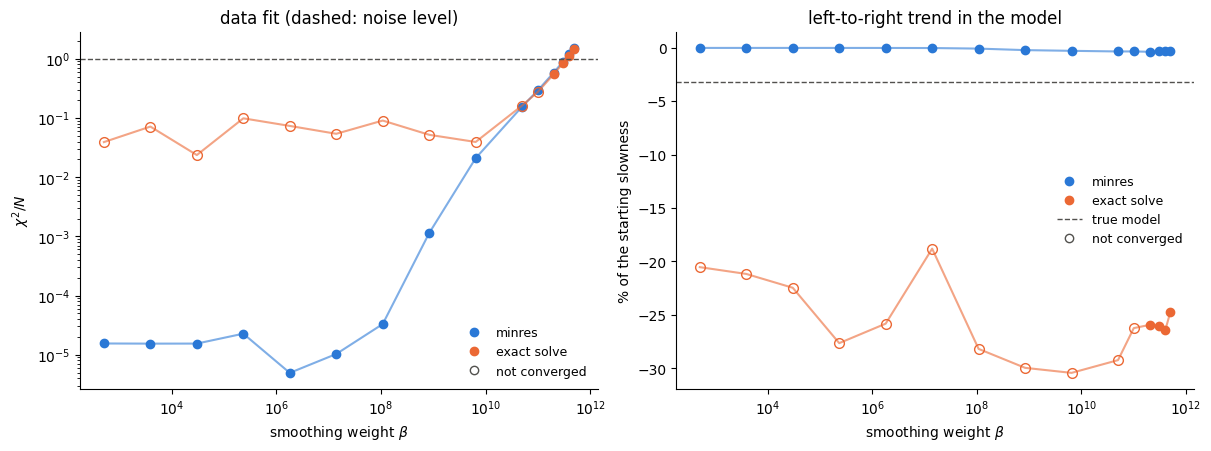

In [7]:
colours = {"minres": "#2a78d6", "exact solve": "#eb6834"}
grey = "#52514e"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for name, by_beta in runs.items():
    ok = [b for b, r in by_beta.items() if not r["failed"]]
    conv = np.array([by_beta[b]["converged"] for b in ok])
    chi2N = np.array([by_beta[b]["chi2"] / data_size for b in ok])
    trend = np.array([100 * left_to_right_trend(by_beta[b]["model"]) for b in ok])
    for ax, ys in [(axes[0], chi2N), (axes[1], trend)]:
        ax.plot(ok, ys, "-", color=colours[name], lw=1.5, alpha=0.6)
        ax.plot(np.array(ok)[conv], ys[conv], "o", color=colours[name], ms=6, label=name)
        ax.plot(np.array(ok)[~conv], ys[~conv], "o", mfc="none", mec=colours[name], ms=7)
axes[0].axhline(1, color=grey, ls="--", lw=1)
axes[0].set(xscale="log", yscale="log", xlabel=r"smoothing weight $\beta$", ylabel=r"$\chi^2/N$",
            title="data fit (dashed: noise level)")
axes[1].axhline(100 * left_to_right_trend(s_true), color=grey, ls="--", lw=1, label="true model")
axes[1].set(xscale="log", xlabel=r"smoothing weight $\beta$", ylabel="% of the starting slowness",
            title="left-to-right trend in the model")
for ax in axes:
    ax.plot([], [], "o", mfc="none", mec=grey, label="not converged")
    ax.legend(frameon=False, fontsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
plt.show()

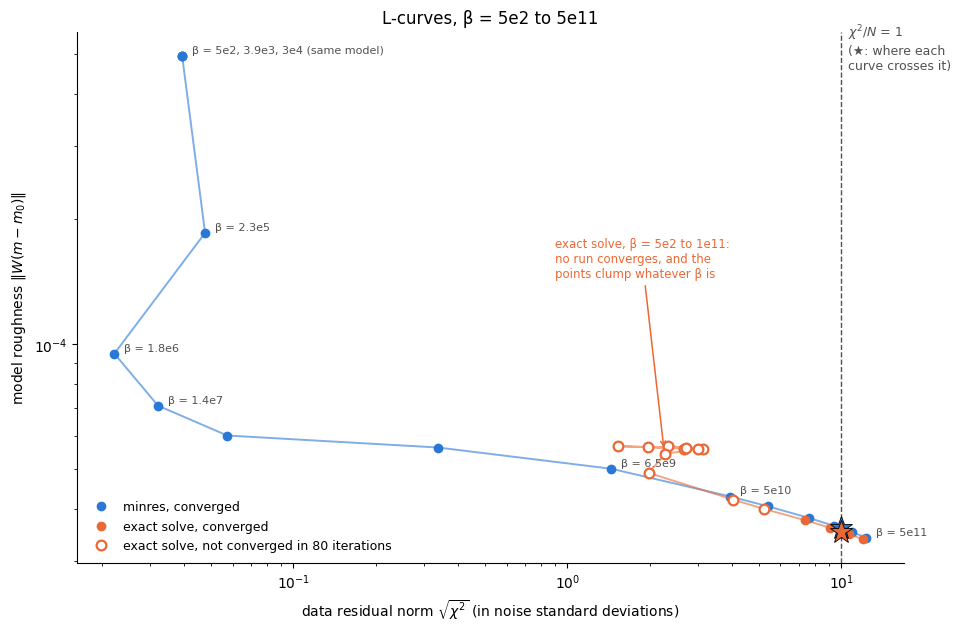

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 6.2), constrained_layout=True)
for name, by_beta in runs.items():
    ok = [b for b in sorted(by_beta) if not by_beta[b]["failed"]]
    misfit = np.sqrt([by_beta[b]["chi2"] for b in ok])
    roughness = np.sqrt([by_beta[b]["roughness"] for b in ok])
    conv = np.array([by_beta[b]["converged"] for b in ok])
    ax.plot(misfit, roughness, "-", color=colours[name], lw=1.4, alpha=0.6)
    ax.plot(misfit[conv], roughness[conv], "o", color=colours[name], ms=6, label=f"{name}, converged")
    if (~conv).any():
        ax.plot(misfit[~conv], roughness[~conv], "o", mfc="white", mec=colours[name], mew=1.6, ms=7,
                label=f"{name}, not converged in 80 iterations")
    # where the curve crosses chi^2/N = 1, interpolated (log-log) between the two runs that bracket it
    chi2N = misfit**2 / data_size
    i = np.flatnonzero((chi2N[:-1] < 1) & (chi2N[1:] >= 1))[0]
    f = -np.log(chi2N[i]) / np.log(chi2N[i + 1] / chi2N[i])
    ax.plot(np.sqrt(data_size), roughness[i] * (roughness[i + 1] / roughness[i])**f, "*", color=colours[name],
            mec="k", mew=0.6, ms=17, zorder=5)

def nearest(by_beta, beta):
    return by_beta[min(by_beta, key=lambda b: abs(np.log(b / beta)))]

labels = {5e2: "β = 5e2, 3.9e3, 3e4 (same model)", 2.3e5: "β = 2.3e5", 1.8e6: "β = 1.8e6", 1.4e7: "β = 1.4e7",
          6.5e9: "β = 6.5e9", 5e10: "β = 5e10", 5e11: "β = 5e11"}
for beta, text in labels.items():
    r = nearest(runs["minres"], beta)
    ax.annotate(text, (np.sqrt(r["chi2"]), np.sqrt(r["roughness"])), textcoords="offset points", xytext=(7, 2),
                fontsize=8, color=grey)
clump = [runs["exact solve"][b] for b in runs["exact solve"] if b <= 1e11 and not runs["exact solve"][b]["failed"]]
cx = np.exp(np.mean(np.log([np.sqrt(r["chi2"]) for r in clump])))
cy = np.exp(np.mean(np.log([np.sqrt(r["roughness"]) for r in clump])))
ax.annotate("exact solve, β = 5e2 to 1e11:\nno run converges, and the\npoints clump whatever β is",
            (cx * 0.85, cy * 1.06), xytext=(0.9, 1.45e-4), fontsize=8.5, color=colours["exact solve"],
            arrowprops=dict(arrowstyle="->", color=colours["exact solve"], lw=1.1))
ax.axvline(np.sqrt(data_size), color=grey, ls="--", lw=1)
ax.text(np.sqrt(data_size) * 1.06, 4.6e-4, "$\\chi^2/N$ = 1\n(★: where each\ncurve crosses it)", fontsize=9, color=grey)
ax.set(xscale="log", yscale="log", xlabel=r"data residual norm $\sqrt{\chi^2}$ (in noise standard deviations)",
       ylabel=r"model roughness $\|W(m-m_0)\|$",
       title="L-curves, β = 5e2 to 5e11")
ax.legend(frameon=False, fontsize=9, loc="lower left")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

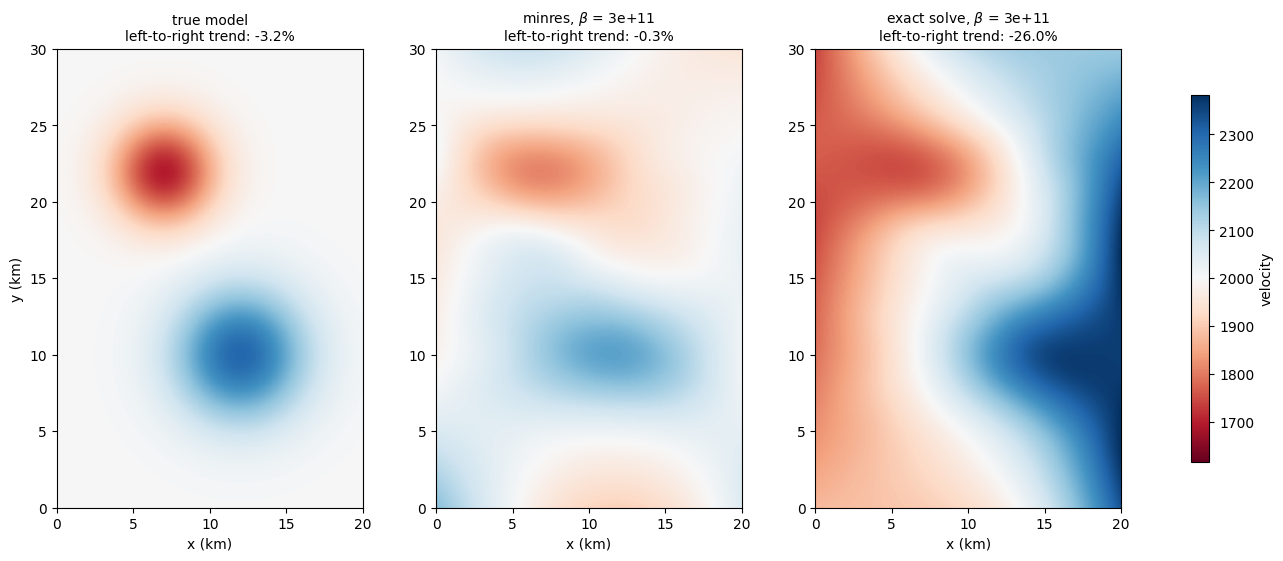

In [9]:
beta_show = 3e11
shown = [("true model", s_true), (f"minres, $\\beta$ = {beta_show:.0e}", runs["minres"][beta_show]["model"]),
         (f"exact solve, $\\beta$ = {beta_show:.0e}", runs["exact solve"][beta_show]["model"])]
velocities = [1. / model.reshape(model_shape) for _, model in shown]
v0, dv = 1. / s0, max(np.abs(v - 1. / s0).max() for v in velocities)
clim = (v0 - dv, v0 + dv)                     # one colour scale for all three, white at the starting velocity
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), constrained_layout=True)
for ax, (title, model), velocity in zip(axes, shown, velocities):
    wt.display_model(velocity, extent=extent, ax=ax, clim=clim, cbar=False,
                     title=f"{title}\nleft-to-right trend: {left_to_right_trend(model):.1%}")
    ax.title.set_fontsize(10)
    ax.set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")
fig.colorbar(axes[-1].images[0], ax=axes, shrink=0.8, label="velocity")
plt.show()

**minres.** Every run converges. $\chi^2/N$ rises with $\beta$ and crosses 1 between $3\times10^{11}$ and
$4\times10^{11}$. The left-to-right trend stays close to zero (at most 0.4%; the true model has about $-3\%$), and the
model at $\beta=3\times10^{11}$ shows the two anomalies, somewhat smoothed.

**Exact solve.** Only the four runs with the largest weights, $\beta=2$ to $5\times10^{11}$, converge. $\chi^2/N=1$ can
still be reached: it lies between the same two weights as for minres, so the data can be fitted to their noise level.
But every model carries a large left-to-right trend, between about $-19\%$ and $-30\%$ of the starting slowness against
about $-3\%$ in the true model; the four that converge all end near $-25\%$. The error is up to about four times that
of minres, and the model at $\beta=3\times10^{11}$ is dominated by the trend.

**The L-curves.** Over the first ten weights, minres traces a classic L-curve. Its corner, near
$\beta\approx2\times10^6$, lies at $\chi^2/N\approx10^{-5}$: a heavily overfitted model. The vertical arm is partly minres's
doing rather than the objective's. For $\beta=5\times10^2$ to $3\times10^4$ minres returns the same model, because it
stops before the smoothing has any effect, and the misfit falls between $\beta=2.3\times10^5$ and $1.8\times10^6$, which
exact minimisers of the objective cannot do: raising $\beta$ can only worsen their fit. The data are fitted to their noise
level only at $\beta\approx3.4\times10^{11}$, far out on the flat arm and beyond the first ten weights.

With the exact solve, no run up to $\beta=10^{11}$ converges, and the points clump at about the same misfit and roughness
whatever $\beta$ is: this is the broken L-curve. The exact-solve runs converge only from $2$ to $5\times10^{11}$, where they
land on the minres curve, and both curves cross $\chi^2/N=1$ at about the same point. There the L-curve cannot tell the
two models apart: the trend that dominates the exact-solve model does not show in the roughness, because the smoothing
does not see a straight trend.

So the exact-solve models are poor whether or not one looks at the L-curve, and the L-curve would not have revealed it.

**Why.** The smoothing does not penalise a straight trend, and the data barely see a left-to-right one, because every ray
runs from the left edge to the right edge (section 2). Almost nothing in
the objective fixes the size of that trend, so the Gauss–Newton system has almost no curvature in that direction. The
exact solve takes the full step along it, and with so little curvature that part of the step is large and erratic.
minres builds its step up gradually, starting with the directions that dominate the system, and stops at its tolerance
before it has built up the ones with almost no curvature. Its stopping rule regularised the inversion implicitly and
held the trend at almost zero.

**Consequence.** An exact solver does exactly what the objective asks, so the objective itself must fix the size of
the trend. Section 4 adds a damping term for this, and shows how to choose its weight $\alpha$ and the overall weight
$\beta$.

## 4. Smoothing plus damping

With an exact solver, the size of the left-to-right trend has to be fixed explicitly by the regularisation. We add a
damping term that pulls the model towards the starting model, and minimise

$$
\phi(m)=\chi^2(m)+\beta\Big[\lVert W(m-m_0)\rVert^2+\alpha\,\lVert m-m_0\rVert^2\Big],
$$

with $\chi^2$ and the smoothing operator $W$ as in section 1. Its Gauss–Newton Hessian is

$$H = 2J^TJ/\sigma^2+2\beta\,(W^TW+\alpha I),$$

where $I$ is the identity matrix. The damping adds $2\alpha\beta I$ to the smoothing-only Hessian: it raises the
curvature along every direction by $2\alpha\beta$, including along the left-to-right ramp, where $J^TJ$ and $W^TW$
give almost none (section 2). Two numbers control the regularisation:

- $\alpha$, the weight of the damping relative to the smoothing, which we set from the size of the model (4.1)
  and which must be small for Gauss–Newton to converge (4.2);
- $\beta$, the overall weight, which we tune by cooling until the data are fitted to their noise level,
  $\chi^2/N\approx 1$ (4.3).

### 4.1 Choosing $\alpha$ from the size of the model

Smoothing and damping both penalise a change to the model, but differently at different length scales. The
smoothing penalises short, rough structure much more than long, smooth structure; the damping penalises all
length scales equally. Their relative weight $\alpha$ sets the length scale $L_c$ at which the two balance:
structure shorter than $L_c$ is controlled mainly by the smoothing, structure longer than $L_c$ mainly by the
damping.

The damping is needed only for what the smoothing cannot control: the trends, which are as long as the model
itself. Everything that fits inside the model should be left to the data and the smoothing. So we set $L_c$ to the
longest side of the model, 48 cells (30 km):

In [10]:
L_c = max(model_shape)                       # cells
alpha = (2 * np.pi / L_c) ** 4
print(f"L_c = {L_c} cells ({L_c * cell_size:.0f} km), alpha = {alpha:.2e}")
print(f"damping relative to smoothing at the scale of the anomalies (25 cells): {alpha / (2 * np.pi / 25) ** 4:.1%}")

L_c = 48 cells (30 km), alpha = 2.94e-04
damping relative to smoothing at the scale of the anomalies (25 cells): 7.4%


With this $\alpha$, here is the first Gauss–Newton step from the starting model at the start of the
cooling ($\beta=10^{14}$), with smoothing only and with smoothing plus damping. The lines are the straight
rays of the starting model.

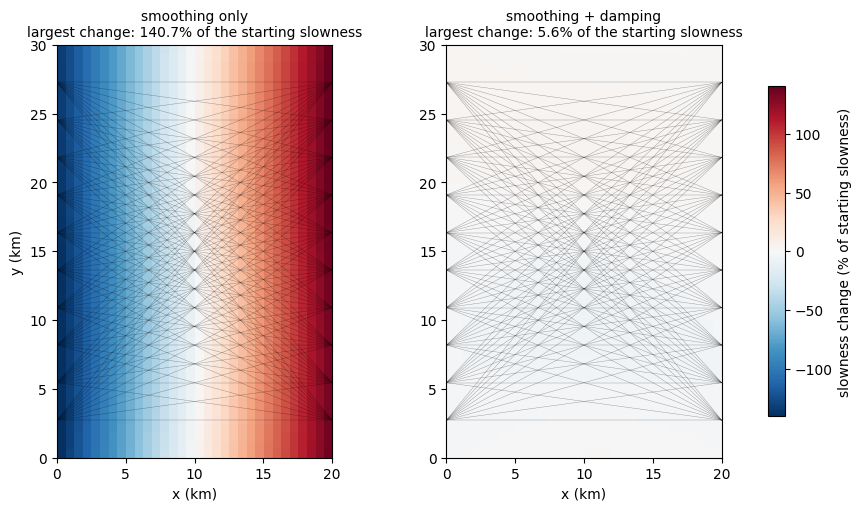

In [11]:
beta_first = 1e14
t_start = fmm_forward_and_jacobian(m0)[0]                      # travel times in the starting model
H_data = 2 * JtJ_start / sigma**2                              # J_start and JtJ_start from section 2
g_start = -2 * J_start.T @ (obstimes - t_start) / sigma**2    # W m0 = 0 for the constant starting model

first_steps = {
    "smoothing only": np.linalg.solve(H_data + 2 * beta_first * WtW, -g_start),
    "smoothing + damping": np.linalg.solve(H_data + 2 * beta_first * (WtW + alpha * np.eye(m0.size)), -g_start),
}
vmax = max(100 * np.abs(step).max() / s0 for step in first_steps.values())
fig, axes = plt.subplots(1, 2, figsize=(9, 5), constrained_layout=True)
for ax, (name, step) in zip(axes, first_steps.items()):
    im = ax.imshow(100 * step.reshape(model_shape).T / s0, origin="lower", extent=extent,
                   cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for src in sources:
        for rec in receivers:
            ax.plot([src[0], rec[0]], [src[1], rec[1]], color="k", lw=0.3, alpha=0.4)
    ax.set_title(f"{name}\nlargest change: {100 * np.abs(step).max() / s0:.1f}% of the starting slowness", fontsize=10)
    ax.set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")
fig.colorbar(im, ax=axes, shrink=0.8, label="slowness change (% of starting slowness)")
plt.show()

With smoothing only, the first step is almost a pure left-to-right ramp, larger than the starting slowness itself
(up to 141%): it would make the slowness negative on one side. With damping, the largest change is about 6%. The damping
therefore stabilises the early Gauss–Newton iterations by keeping this large ramp out of the steps. Both
panels share the same colour scale, which is why the damped step looks almost blank.

### 4.2 Why the smoothing must dominate the damping

The damping is needed, but it must stay weak compared with the smoothing at the length scales inside the model,
otherwise Gauss–Newton stops converging. To see why, look at what each Gauss–Newton step builds. The step spreads
the data residuals back along the current rays, which on its own would give thin streaks along the ray paths, and
the regularisation then reshapes them: the smoothing blurs the streaks into broad anomalies, while the damping only
scales them.

The rays bend in response to the new model. A ray that moves sideways by about the width of a thin streak no
longer sees it, so the next step removes that streak and paints a new one along the new path, which moves the rays
again: the model chases the rays and the iteration does not settle. A ray that moves a little inside a broad anomaly
still sees it, and the iteration converges.

The figure compares plain Gauss–Newton (full steps from the starting model) for two regularisations with the same
damping weight $\alpha\beta\approx9\times10^7$. In the first, $\alpha=10^4$, so the damping dominates at every length
scale. The second uses the $\alpha$ from 4.1 with $\beta=3\times10^{11}$, about where the cooling in 4.3 ends.

In [12]:
def fmm_with_paths(slowness):
    """Travel times, Frechet derivatives and ray paths from a single FMM run"""
    options = wt.WaveTrackerOptions(paths=True, frechet=True, cartesian=True, quiet=True)
    result = wt.calc_wavefronts(1./slowness.reshape(model_shape), receivers, sources,
                                extent=extent, options=options)
    return result.ttimes, result.frechet.toarray(), [np.asarray(path) for path in result.paths]

def plain_gauss_newton(beta, alpha, num_iterations=8):
    """Full Gauss-Newton steps from the starting model, keeping the model, the ray paths and the
    objective at every iterate"""
    model, iterates = m0.copy(), []
    for k in range(num_iterations + 1):
        t, J, paths = fmm_with_paths(model)
        residual, x = obstimes - t, model - m0
        objective = residual @ residual / sigma**2 + beta * (x @ WtW @ x + alpha * x @ x)
        iterates.append({"model": model, "paths": paths, "objective": objective})
        if k == num_iterations:
            break
        hessian = 2 * J.T @ J / sigma**2 + 2 * beta * (WtW + alpha * np.eye(m0.size))
        gradient = -2 * J.T @ residual / sigma**2 + 2 * beta * (WtW @ x + alpha * x)   # W m0 = 0
        model = model + np.linalg.solve(hessian, -gradient)
    return iterates

def path_shift(path_a, path_b):
    """Largest sideways distance (km) between two paths of the same ray"""
    xs = np.linspace(extent[0] + 0.5, extent[1] - 0.5, 200)
    ya, yb = (np.interp(xs, *path[np.argsort(path[:, 0])].T) for path in (path_a, path_b))
    return np.abs(ya - yb).max()

beta_demo = 3e11                                                # about where the cooling in 4.3 ends
cases = {"damping dominates": (alpha * beta_demo / 1e4, 1e4),   # (beta, alpha): the same damping weight alpha * beta
         "smoothing dominates": (beta_demo, alpha)}             # the alpha chosen in 4.1
damping_runs = {name: plain_gauss_newton(beta, a) for name, (beta, a) in cases.items()}

for name, iterates in damping_runs.items():
    beta, a = cases[name]
    shifts = [max(path_shift(p, q) for p, q in zip(iterates[j - 1]["paths"], iterates[j]["paths"]))
              for j in range(1, len(iterates))]
    steps = [100 * np.abs(iterates[j]["model"] - iterates[j - 1]["model"]).max() / s0
             for j in range(1, len(iterates))]
    print(f"{name}: alpha = {a:.1e}, beta = {beta:.2e}, damping weight alpha*beta = {a * beta:.1e}")
    print("  objective:                " + "  ".join(f"{it['objective']:.2e}" for it in iterates))
    print("  largest ray shift (km):   " + "  ".join(f"{s:.2f}" for s in shifts))
    print("  largest step (% of s0):   " + "  ".join(f"{s:.1f}" for s in steps))

damping dominates: alpha = 1.0e+04, beta = 8.81e+03, damping weight alpha*beta = 8.8e+07
  objective:                1.84e+05  2.80e+03  5.88e+03  6.71e+03  4.89e+03  4.13e+03  4.34e+03  3.90e+03  3.29e+03
  largest ray shift (km):   1.95  2.19  1.61  1.74  1.52  1.53  1.51  1.51
  largest step (% of s0):   10.6  10.3  15.7  15.8  13.7  12.3  11.2  10.8
smoothing dominates: alpha = 2.9e-04, beta = 3.00e+11, damping weight alpha*beta = 8.8e+07
  objective:                1.84e+05  2.51e+03  5.35e+02  5.32e+02  5.32e+02  5.32e+02  5.32e+02  5.32e+02  5.32e+02
  largest ray shift (km):   2.06  0.60  0.15  0.03  0.01  0.00  0.00  0.00
  largest step (% of s0):   10.2  2.2  1.0  0.2  0.0  0.0  0.0  0.0


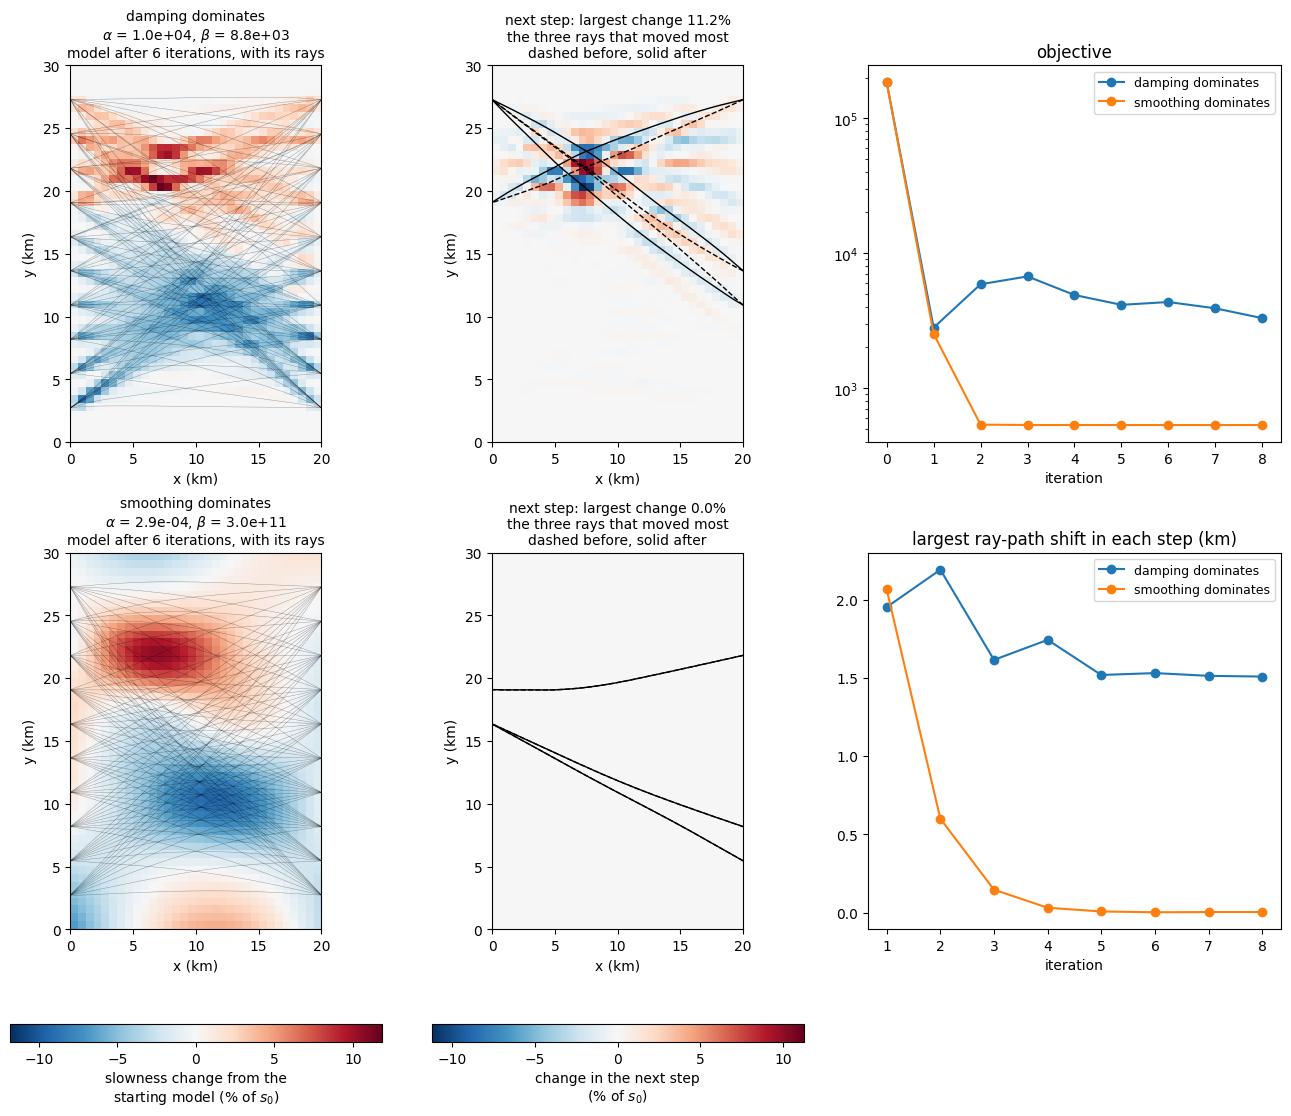

In [13]:
k = 6
fig, axes = plt.subplot_mosaic([["change0", "step0", "objective"], ["change1", "step1", "shift"]],
                               figsize=(13, 11), constrained_layout=True)
change_max = max(100 * np.abs(it[k]["model"] - m0).max() / s0 for it in damping_runs.values())
step_max = max(100 * np.abs(it[k + 1]["model"] - it[k]["model"]).max() / s0 for it in damping_runs.values())
for row, (name, iterates) in enumerate(damping_runs.items()):
    beta, a = cases[name]
    change = 100 * (iterates[k]["model"] - m0) / s0
    step = 100 * (iterates[k + 1]["model"] - iterates[k]["model"]) / s0
    shifts = np.array([path_shift(p, q) for p, q in zip(iterates[k]["paths"], iterates[k + 1]["paths"])])

    ax = axes[f"change{row}"]
    im_change = ax.imshow(change.reshape(model_shape).T, origin="lower", extent=extent,
                          cmap="RdBu_r", vmin=-change_max, vmax=change_max)
    for path in iterates[k]["paths"]:
        ax.plot(*path.T, color="k", lw=0.3, alpha=0.4)
    ax.set_title(f"{name}\n$\\alpha$ = {a:.1e}, $\\beta$ = {beta:.1e}\nmodel after {k} iterations, with its rays",
                 fontsize=10)

    ax = axes[f"step{row}"]
    im_step = ax.imshow(step.reshape(model_shape).T, origin="lower", extent=extent,
                        cmap="RdBu_r", vmin=-step_max, vmax=step_max)
    for i in np.argsort(shifts)[-3:]:                     # the three rays that moved most in this step
        ax.plot(*iterates[k]["paths"][i].T, "k--", lw=1)
        ax.plot(*iterates[k + 1]["paths"][i].T, "k-", lw=1)
    ax.set_title(f"next step: largest change {np.abs(step).max():.1f}%\n"
                 f"the three rays that moved most\ndashed before, solid after", fontsize=10)

    axes["objective"].semilogy([it["objective"] for it in iterates], "o-", label=name)
    axes["shift"].plot(range(1, len(iterates)),
                       [max(path_shift(p, q) for p, q in zip(iterates[j - 1]["paths"], iterates[j]["paths"]))
                        for j in range(1, len(iterates))], "o-", label=name)

for key in ["change0", "change1", "step0", "step1"]:
    axes[key].set_xlabel("x (km)")
    axes[key].set_ylabel("y (km)")
fig.colorbar(im_change, ax=[axes["change0"], axes["change1"]], location="bottom", shrink=0.9,
             label="slowness change from the\nstarting model (% of $s_0$)")
fig.colorbar(im_step, ax=[axes["step0"], axes["step1"]], location="bottom", shrink=0.9,
             label="change in the next step\n(% of $s_0$)")
axes["objective"].set(title="objective", xlabel="iteration")
axes["shift"].set(title="largest ray-path shift in each step (km)", xlabel="iteration")
axes["objective"].legend(fontsize=9)
axes["shift"].legend(fontsize=9)
plt.show()

With the damping dominating and the smoothing weak (top row), the regularisation leaves thin features in the model:
streaks along the ray paths. The smoothing is too weak to blur them out, so the model changes a lot from one iteration
to the next, and the rays move a lot with it. In every iteration some ray moves by 1.5–2.2 km, every step changes the
slowness by 10–16%, and the objective bounces between about $3\times10^3$ and $7\times10^3$ instead of settling. More
damping does not help: it makes the streaks weaker, but not wider.

With the smoothing dominating (bottom row), the fine features are blurred out and the model is made of broad
anomalies. The rays move by up to about 2 km in the first step, but they stay inside the broad anomalies, so the model
changes less and less. From the fourth step on, the rays move by less than 0.05 km, each step changes the slowness by
0.2% or less, and the objective has settled.

### 4.3 Choosing $\beta$ by cooling to $\chi^2/N\approx 1$

$\beta$ sets the balance between fitting the data and keeping the model regular. Because the noise level $\sigma$
is known, we choose the $\beta$ at which the data are fitted to their noise level, $\chi^2/N\approx 1$ (the
discrepancy principle): a larger $\beta$ leaves signal in the residuals, a smaller one starts fitting the noise.

We find it by cooling. We start with $\beta$ so large that the regularisation dominates, so the first Gauss–Newton
steps are small and smooth. We then halve $\beta$ stage by stage, starting each stage from the previous stage's
model, until $\chi^2/N$ drops below 1, and finally interpolate to $\chi^2/N=1$. Each stage is a full Gauss–Newton
inversion with `cofi.simple_newton`, run until no cell changes by more than 0.2% of the starting slowness in an
iteration, for at most 20 iterations. In this example, plain Gauss–Newton started directly at the final $\beta$ would also converge (4.2);
the main job of the cooling here is to find that $\beta$, and it keeps the method safe when the starting model is
far from the solution.

Each stage is a CoFI problem whose forward function returns the travel times and the Jacobian from a single FMM
run (`BaseProblem.set_forward_and_jacobian`). CoFI caches the result for the most recent model, so the gradient
and the Gauss–Newton Hessian, written below in terms of `problem.forward` and `problem.jacobian`, reuse that run:
each Newton iteration needs one FMM run instead of three.

In [14]:
reg_smoothing = cofi.utils.QuadraticReg(model_shape=model_shape, weighting_matrix="smoothing")   # W of section 1
reg_damping = cofi.utils.QuadraticReg(model_shape=model_shape, weighting_matrix="damping",
                                      reference_model=m0.reshape(model_shape))

def gauss_newton_gradient(model, problem, reg):
    residual = problem.data - problem.forward(model)
    J = problem.jacobian(model)                      # same model: served from the cache
    return -2 * J.T @ (problem.data_covariance_inv @ residual) + reg.gradient(model)

def gauss_newton_hessian(model, problem, reg):
    J = problem.jacobian(model)
    return np.asarray(2 * J.T @ problem.data_covariance_inv @ J + reg.hessian(model))

def make_problem(beta, alpha, initial_model):
    reg = beta * (reg_smoothing + alpha * reg_damping)
    problem = cofi.BaseProblem()
    problem.set_forward_and_jacobian(fmm_forward_and_jacobian)   # one FMM run per model
    problem.set_data(obstimes, data_cov_inv=np.eye(data_size) / sigma**2)
    problem.set_data_misfit("squared error")                     # chi^2
    problem.set_regularization(reg)                              # objective = chi^2 + reg
    problem.set_gradient(gauss_newton_gradient, args=[problem, reg])
    problem.set_hessian(gauss_newton_hessian, args=[problem, reg])
    problem.set_initial_model(initial_model)
    return problem

In [15]:
max_iterations = 20
stage_options = cofi.InversionOptions()
stage_options.set_tool("cofi.simple_newton")
stage_options.set_params(num_iterations=max_iterations, step_length=1, hessian_is_symmetric=True,
                         obj_tol=1e-16, param_tol=1e-6, verbose=False)

def run_stage(beta, alpha, initial_model):
    problem = make_problem(beta, alpha, initial_model)
    result = cofi.Inversion(problem, stage_options).run()
    iterations = result.num_iterations + 1
    return {"beta": beta, "model": result.model, "chi2": problem.data_misfit(result.model),
            "reg": reg_smoothing(result.model) + alpha * reg_damping(result.model),
            "iterations": iterations, "converged": iterations < max_iterations}

def cool(alpha, beta0=1e14, factor=2.0, verbose=True):
    """Reduce beta from beta0 by `factor` per stage until chi^2/N < 1, warm-starting every stage,
    then interpolate log(beta) to chi^2/N = 1"""
    def report(stage, note=""):
        if verbose:
            print(f"{stage['beta']:10.3e} {stage['chi2'] / data_size:9.3f} {stage['iterations']:11d}  {note}")
    if verbose:
        print(f"{'beta':>10} {'chi2/N':>9} {'iterations':>11}")
    stages, model, beta = [], m0.copy(), beta0
    while True:
        stage = run_stage(beta, alpha, model)
        stages.append(stage)
        report(stage)
        model = stage["model"]
        if stage["chi2"] / data_size <= 1:
            break
        beta /= factor
    upper, lower = stages[-2], stages[-1]
    for _ in range(3):
        x0, x1 = np.log(upper["beta"]), np.log(lower["beta"])
        y0, y1 = np.log(upper["chi2"] / data_size), np.log(lower["chi2"] / data_size)
        final = run_stage(np.exp(x0 - y0 * (x1 - x0) / (y1 - y0)), alpha, upper["model"])
        report(final, "(interpolated)")
        if abs(final["chi2"] / data_size - 1) < 0.02:
            break
        if final["chi2"] / data_size > 1:
            upper = final
        else:
            lower = final
    return stages, final

In [16]:
stages, final = cool(alpha)
print(f"\nbeta* = {final['beta']:.3e}: smoothing weight {final['beta']:.2e}, damping weight {alpha * final['beta']:.2e}, "
      f"chi2/N = {final['chi2'] / data_size:.3f}")

      beta    chi2/N  iterations


 1.000e+14   133.657           3  


 5.000e+13    80.882           2  


 2.500e+13    47.814           2  


 1.250e+13    27.908           2  


 6.250e+12    16.167           2  


... (2 outputs left out)

 7.812e+11     2.455           2  


 3.906e+11     1.180           2  


 1.953e+11     0.569           2  


 3.339e+11     0.995           1  (interpolated)

beta* = 3.339e+11: smoothing weight 3.34e+11, damping weight 9.80e+07, chi2/N = 0.995


### 4.4 Results

The true model and the inverted model at $\chi^2/N\approx 1$, and the data residuals normalised by $\sigma$:

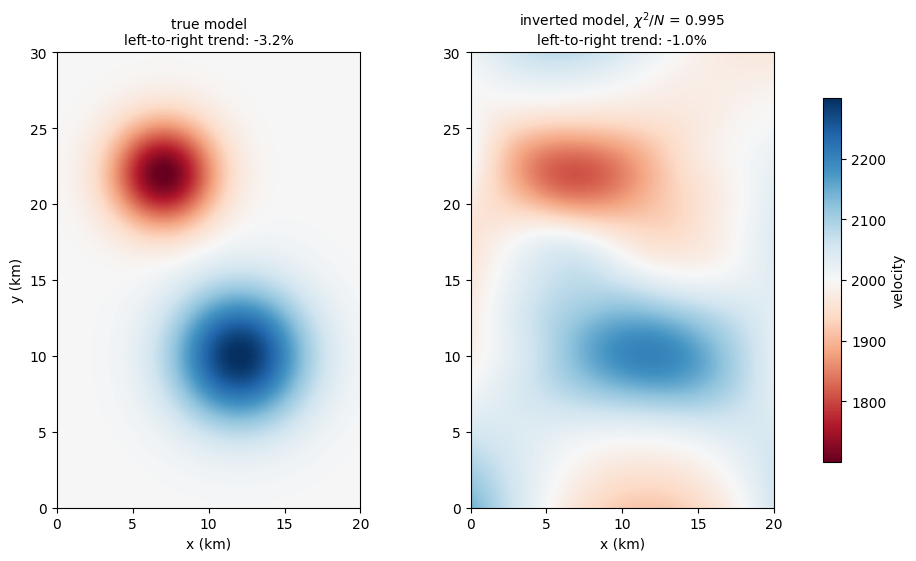

In [17]:
shown = [("true model", s_true), (f"inverted model, $\\chi^2/N$ = {final['chi2'] / data_size:.3f}", final["model"])]
velocities = [1. / model.reshape(model_shape) for _, model in shown]
v0, dv = 1. / s0, max(np.abs(v - 1. / s0).max() for v in velocities)
clim = (v0 - dv, v0 + dv)                     # one colour scale for both, white at the starting velocity
fig, axes = plt.subplots(1, 2, figsize=(9.5, 5.5), constrained_layout=True)
for ax, (title, model), velocity in zip(axes, shown, velocities):
    wt.display_model(velocity, extent=extent, ax=ax, clim=clim, cbar=False,
                     title=f"{title}\nleft-to-right trend: {left_to_right_trend(model):.1%}")
    ax.title.set_fontsize(10)
    ax.set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")
fig.colorbar(axes[-1].images[0], ax=axes, shrink=0.8, label="velocity")
plt.show()

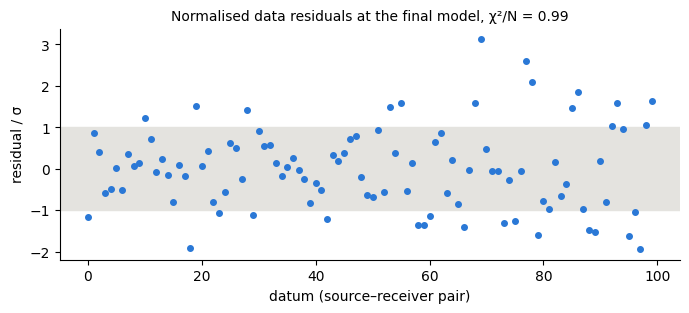

In [18]:
normalised_residuals = (obstimes - fmm_forward_and_jacobian(final["model"])[0]) / sigma
fig, ax = plt.subplots(figsize=(8, 3))
ax.axhspan(-1, 1, color="#e4e3df", label="±1")
ax.plot(normalised_residuals, "o", ms=4, color="#2a78d6")
ax.set_xlabel("datum (source–receiver pair)")
ax.set_ylabel("residual / σ")
ax.set_title(f"Normalised data residuals at the final model, χ²/N = {np.mean(normalised_residuals**2):.2f}", fontsize=10)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

### 4.5 The L-curve as a cross-check

Every cooling stage is a converged solution for its $\beta$, so the stages trace out the L-curve: the size of the
data residuals against the size of the regularisation term. When the noise level is unknown, the corner of the
L-curve is a common way to choose $\beta$. Here $\sigma$ is known, so $\chi^2/N\approx 1$ is our criterion and the
L-curve is only a cross-check. We continue the cooling for four more stages below $\chi^2/N=1$ to show the rest of
the curve; stages that do not converge within 20 iterations are shown with open markers.

 9.766e+10     0.286           3  converged: True


 4.883e+10     0.152           2  converged: True


 2.441e+10     0.085          20  converged: False


 1.221e+10     0.055          20  converged: False


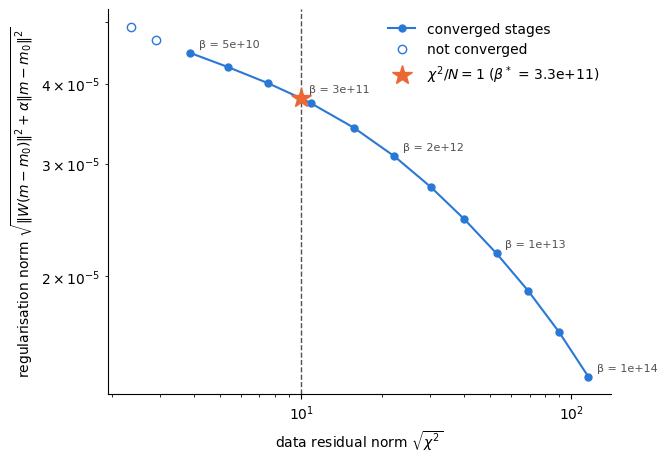

In [19]:
beyond, model, beta = [], stages[-1]["model"], stages[-1]["beta"]
for _ in range(4):
    beta /= 2
    stage = run_stage(beta, alpha, model)
    beyond.append(stage)
    model = stage["model"]
    print(f"{beta:10.3e} {stage['chi2'] / data_size:9.3f} {stage['iterations']:11d}  converged: {stage['converged']}")

curve = sorted(stages + [final] + beyond, key=lambda s: -s["beta"])
converged = [s for s in curve if s["converged"]]
not_converged = [s for s in curve if not s["converged"]]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([np.sqrt(s["chi2"]) for s in converged], [np.sqrt(s["reg"]) for s in converged],
        "-o", color="#2a78d6", ms=5, lw=1.5, label="converged stages")
if not_converged:
    ax.plot([np.sqrt(s["chi2"]) for s in not_converged], [np.sqrt(s["reg"]) for s in not_converged],
            "o", mfc="none", mec="#2a78d6", ms=6, label="not converged")
ax.plot(np.sqrt(final["chi2"]), np.sqrt(final["reg"]), "*", color="#eb6834", ms=15, zorder=3,
        label=f"$\\chi^2/N=1$ ($\\beta^*$ = {final['beta']:.1e})")
ax.axvline(np.sqrt(data_size), color="#52514e", ls="--", lw=1)
for s in converged[::3]:
    ax.annotate(f"β = {s['beta']:.0e}", (np.sqrt(s["chi2"]), np.sqrt(s["reg"])),
                textcoords="offset points", xytext=(6, 4), fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"data residual norm $\sqrt{\chi^2}$")
ax.set_ylabel(r"regularisation norm $\sqrt{\|W(m-m_0)\|^2+\alpha\|m-m_0\|^2}$")
ax.legend(frameon=False)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

Over the range where the cooling converges (down to $\chi^2/N\approx0.15$), the L-curve has no corner: in log–log
axes it bends only gradually, and every further reduction of $\beta$ keeps buying a better data fit at a moderate cost
in regularisation. A corner, if there is one, would lie further into the overfitting regime, $\chi^2/N\ll1$, where
plain Gauss–Newton no longer converges (open markers). So the L-curve does not pick $\beta$ here; with a known noise
level, $\chi^2/N\approx1$ is the more reliable criterion.

### 4.6 What a longer length scale does

$L_c$ is a choice, so we check what happens if it is longer than the model. With $L_c$ = 96 cells, twice the
longest side, $\alpha$ is 16 times smaller, and so is the damping relative to the smoothing. We repeat the cooling
and compare the result with the one above and with the true model.

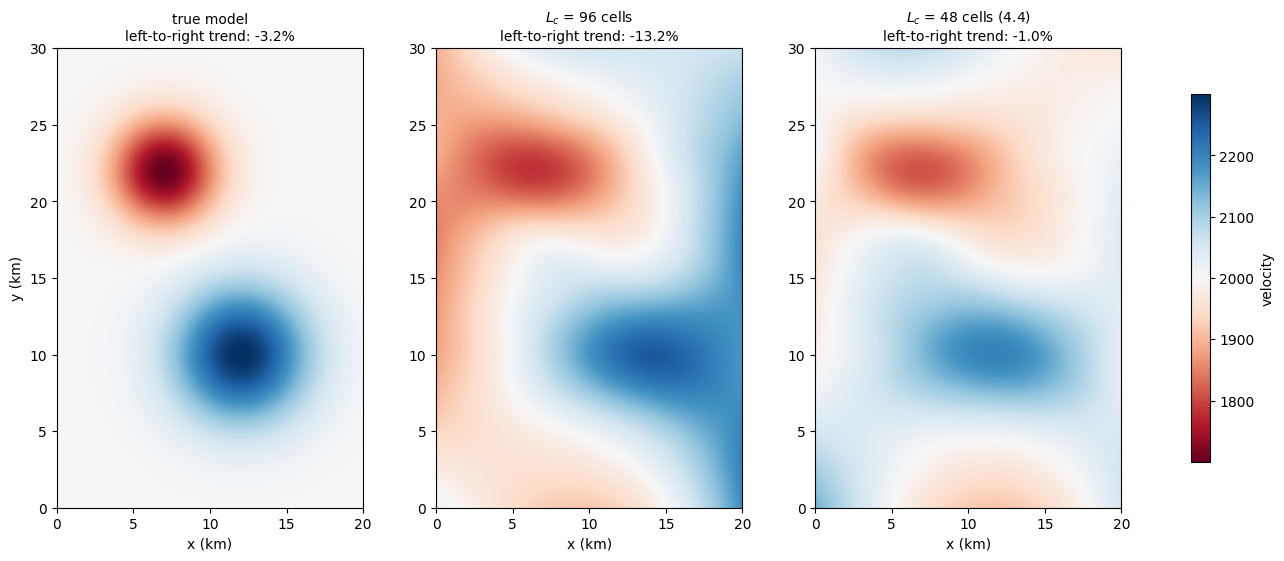

L_c = 96 cells: beta* = 3.47e+11, chi2/N = 0.995, rms difference from the true model = 3.7% of the starting slowness
L_c = 48 cells: beta* = 3.34e+11, chi2/N = 0.995, rms difference from the true model = 2.2% of the starting slowness


In [20]:
_, final_long = cool(alpha / 16, verbose=False)                # L_c = 96 cells

shown = [("true model", s_true), ("$L_c$ = 96 cells", final_long["model"]), ("$L_c$ = 48 cells (4.4)", final["model"])]
velocities = [1. / model.reshape(model_shape) for _, model in shown]
v0, dv = 1. / s0, max(np.abs(v - 1. / s0).max() for v in velocities)
clim = (v0 - dv, v0 + dv)                     # one colour scale for all three, white at the starting velocity
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), constrained_layout=True)
for ax, (title, model), velocity in zip(axes, shown, velocities):
    wt.display_model(velocity, extent=extent, ax=ax, clim=clim, cbar=False,
                     title=f"{title}\nleft-to-right trend: {left_to_right_trend(model):.1%}")
    ax.title.set_fontsize(10)
    ax.set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")
fig.colorbar(axes[-1].images[0], ax=axes, shrink=0.8, label="velocity")
plt.show()

for name, stage in [("L_c = 96 cells", final_long), ("L_c = 48 cells", final)]:
    error = np.sqrt(np.mean((stage["model"] - s_true)**2)) / s0
    print(f"{name}: beta* = {stage['beta']:.2e}, chi2/N = {stage['chi2'] / data_size:.3f}, "
          f"rms difference from the true model = {error:.1%} of the starting slowness")

With $L_c$ = 96 cells the damping is too weak to fix the size of the left-to-right trend: the model is slower on the
left and faster on the right by about 13% of the starting slowness, four times the true model's 3%, and its rms
difference from the true model is 3.7% instead of 2.2%. The anomalies themselves are almost the same. With $L_c$ = 48
cells the trend is about 1%, smaller than the true model's: the data cannot see it, so the damping keeps it near
zero. The length scale mainly decides the size of the trend, and the size of the model is the natural choice.

---
## Watermark

In [21]:
watermark_list = ["cofi", "numpy", "matplotlib"]
for pkg in watermark_list:
    pkg_var = __import__(pkg)
    print(pkg, getattr(pkg_var, "__version__"))

cofi 0.2.12+6.g4975fd9
numpy 2.4.3
matplotlib 3.10.8
